# 02 - The unlabelled data: which rooms, how they relate, what the "usual picture" looks like

Questions:
1. Which rooms are in the unlabelled set, and do they look like the labelled rooms?
2. Can the "unknown" traces be matched to a known room?
3. How much do people move in each unlabelled room (does each room seem to contain several headcounts)?
4. Which interference (spikes) does each room have?
5. Does "distance from the room's usual picture" carry headcount information? (tested on labelled rooms a, c, g)

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import data, dsp

lab = data.load_index("labeled"); lab["set"] = "L"
unl = data.load_index("unlabeled"); unl["set"] = "U"; unl["headcount"] = -1
idx = pd.concat([lab, unl], ignore_index=True)
idx.groupby(["set", "layout"]).size().unstack(0).fillna(0).astype(int)

set,L,U
layout,,
a,12,0
b,1,0
c,12,0
d,0,8
e,3,0
g,17,0
h,0,14
i,0,17
j,0,4


## Per-window numbers for every trace (labelled + unlabelled)
3 windows of 600 frames per trace (start, middle, end). Takes a few minutes: every trace is ~300 MB.

In [2]:
rows, profiles = [], []
for _, r in idx.iterrows():
    csi, ati = data.load_trace(r.identifier, "labeled" if r.set == "L" else "unlabeled")
    csi = dsp.normalize_gain(csi)
    for s, w, a in data.windows(csi, ati, step=5700):
        clean = dsp.clean(w)
        rows.append({"id": r.identifier, "set": r.set, "layout": r.layout, "headcount": r.headcount, "start": s,
                     "dyn_ratio": dsp.dynamic_ratio(clean),
                     **{f"spike_b{k}": v for k, v in enumerate(dsp.spike_fraction(w))},
                     **dsp.ati_stats(a)})
        profiles.append(dsp.static_profile(clean))
win = pd.DataFrame(rows)
prof = np.array(profiles)
np.savez("../cache/all_windows_summary.npz", prof=prof)
win.to_csv("../cache/all_windows_summary.csv", index=False)
len(win), prof.shape

(594, (594, 3039))

## 1. Static profile similarity: all rooms, labelled (L) and unlabelled (U)
One row/column per trace (profile averaged over its 3 windows). Bright = same-looking frozen picture.
Lines separate rooms.

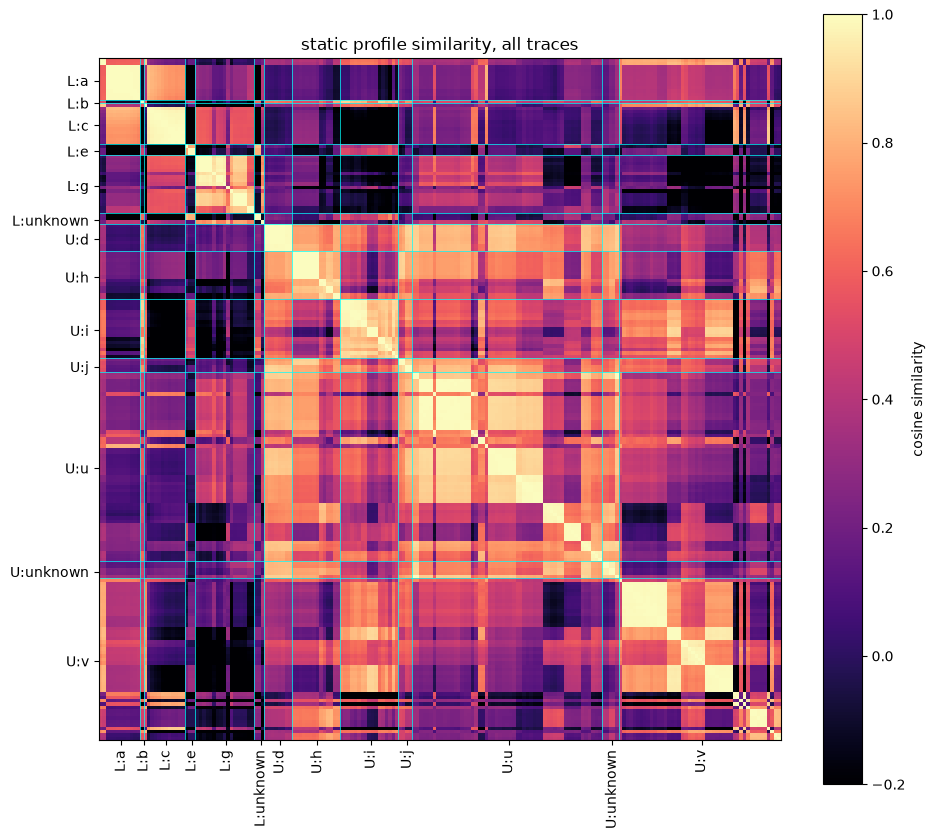

In [3]:
tr = win.groupby("id", sort=False).agg(set=("set", "first"), layout=("layout", "first"),
                                       headcount=("headcount", "first")).reset_index()
P = np.array([prof[(win.id == t).values].mean(0) for t in tr.id])
P = (P - P.mean(1, keepdims=True)) / P.std(1, keepdims=True)
tr["key"] = tr.set + ":" + tr.layout
order = tr.sort_values(["set", "layout"]).index.values
S = P[order] @ P[order].T / P.shape[1]
keys = tr.key.values[order]

fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(S, cmap="magma", vmin=-0.2, vmax=1)
bounds = [i for i in range(1, len(keys)) if keys[i] != keys[i - 1]]
for b in bounds:
    ax.axhline(b - 0.5, color="cyan", lw=0.5); ax.axvline(b - 0.5, color="cyan", lw=0.5)
starts = [0] + bounds; ends = bounds + [len(keys)]
centers = [(s + e) / 2 for s, e in zip(starts, ends)]
ax.set_xticks(centers); ax.set_xticklabels([keys[s] for s in starts], rotation=90)
ax.set_yticks(centers); ax.set_yticklabels([keys[s] for s in starts])
plt.colorbar(im, label="cosine similarity"); ax.set_title("static profile similarity, all traces")
plt.show()

In [4]:
# Average similarity between every pair of rooms (diagonal = inside one room)
groups = sorted(tr.key.unique())
M = pd.DataFrame(index=groups, columns=groups, dtype=float)
Sfull = P @ P.T / P.shape[1]
for g1 in groups:
    for g2 in groups:
        i1 = np.where(tr.key == g1)[0]; i2 = np.where(tr.key == g2)[0]
        block = Sfull[np.ix_(i1, i2)]
        if g1 == g2:
            block = block[~np.eye(len(i1), dtype=bool)] if len(i1) > 1 else np.array([np.nan])
        M.loc[g1, g2] = block.mean()
M.round(2)

,L:a,L:b,L:c,L:e,L:g,L:unknown,U:d,U:h,U:i,U:j,U:u,U:unknown,U:v
L:a,0.88,0.00,0.65,-0.17,0.22,-0.04,0.10,0.14,0.14,0.23,0.23,0.22,0.42
L:b,0.00,NaN,-0.22,0.44,-0.11,0.41,0.65,0.57,0.82,0.65,0.48,0.47,0.47
L:c,0.65,-0.22,0.82,-0.36,0.45,-0.15,0.02,0.17,-0.24,0.10,0.18,0.22,0.12
L:e,-0.17,0.44,-0.36,0.86,-0.07,0.58,0.09,-0.07,0.47,0.00,0.04,0.02,0.08
L:g,0.22,-0.11,0.45,-0.07,0.81,0.13,0.16,0.04,-0.14,0.08,0.29,0.24,-0.09
L:unknown,-0.04,0.41,-0.15,0.58,0.13,0.25,0.21,0.04,0.40,0.12,0.18,0.16,0.10
U:d,0.10,0.65,0.02,0.09,0.16,0.21,0.99,0.75,0.59,0.82,0.74,0.84,0.34
U:h,0.14,0.57,0.17,-0.07,0.04,0.04,0.75,0.88,0.35,0.77,0.57,0.73,0.36
U:i,0.14,0.82,-0.24,0.47,-0.14,0.40,0.59,0.35,0.89,0.58,0.44,0.38,0.50
U:j,0.23,0.65,0.10,0.00,0.08,0.12,0.82,0.77,0.58,0.93,0.67,0.66,0.49


## 2. Where do the 'unknown' traces belong? Closest known room for each

In [5]:
known = tr[tr.layout != "unknown"]
for i in np.where(tr.layout == "unknown")[0]:
    sims = {k: Sfull[i, np.where(tr.key == k)[0]].mean() for k in known.key.unique()}
    best = sorted(sims.items(), key=lambda kv: -kv[1])[:3]
    print(f"{tr.set[i]}:{tr.id[i]:32s} hc={tr.headcount[i]:>2}  closest: " +
          ", ".join(f"{k} {v:.2f}" for k, v in best))

L:unknown_unknown_hash287936_1     hc= 1  closest: L:e 0.82, L:b 0.62, U:i 0.52
L:unknown_unknown_hash461239_1     hc= 1  closest: L:e 0.82, L:b 0.63, U:i 0.53
L:unknown_unknown_hash081247_1     hc= 1  closest: L:g 0.73, L:a 0.39, U:u 0.34
U:unknown_unknown_hash327110_unlabeled hc=-1  closest: U:d 0.83, U:h 0.70, U:u 0.69
U:unknown_unknown_hash603766_unlabeled hc=-1  closest: U:d 0.82, U:h 0.69, U:u 0.69
U:unknown_unknown_hash710250_unlabeled hc=-1  closest: U:d 0.83, U:h 0.77, U:u 0.68
U:unknown_unknown_hash952134_unlabeled hc=-1  closest: U:d 0.83, U:h 0.77, U:u 0.68
U:unknown_unknown_hash393537_unlabeled hc=-1  closest: U:d 0.88, U:u 0.79, U:j 0.77


## 3. How much movement in each room?
Each dot is one window. Labelled rooms are coloured by headcount, unlabelled rooms are grey.
A room whose dots spread over a wide range probably contains recordings with different headcounts / behaviours.

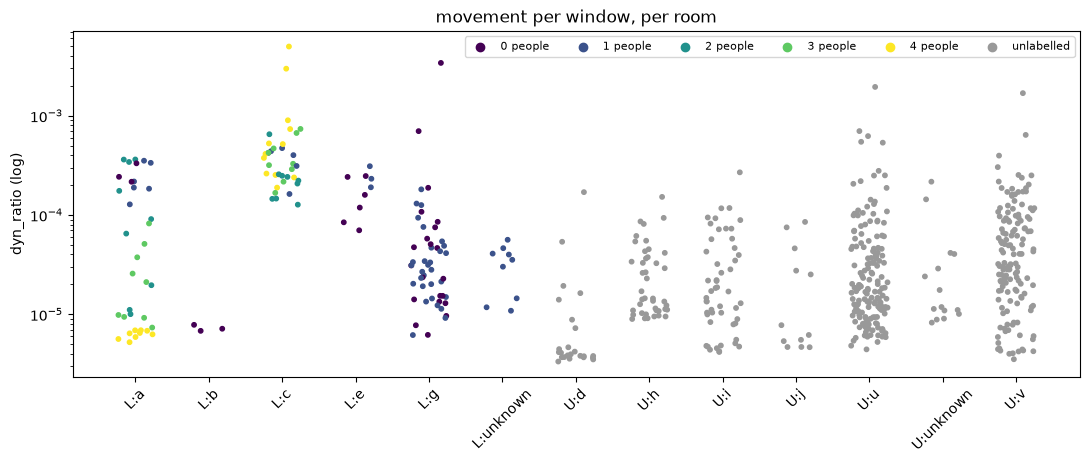

In [6]:
fig, ax = plt.subplots(figsize=(13, 4.5))
keys_sorted = sorted(win.assign(key=win.set + ":" + win.layout).key.unique())
cmap = plt.get_cmap("viridis", 5)
for x, k in enumerate(keys_sorted):
    d = win[(win.set + ":" + win.layout) == k]
    jitter = np.random.uniform(-0.25, 0.25, len(d))
    c = ["0.6" if h < 0 else cmap(h) for h in d.headcount]
    ax.scatter(x + jitter, d.dyn_ratio, s=10, c=c)
ax.set_yscale("log"); ax.set_xticks(range(len(keys_sorted))); ax.set_xticklabels(keys_sorted, rotation=45)
for h in range(5):
    ax.scatter([], [], c=[cmap(h)], label=f"{h} people")
ax.scatter([], [], c="0.6", label="unlabelled"); ax.legend(ncol=6, fontsize=8)
ax.set_ylabel("dyn_ratio (log)"); ax.set_title("movement per window, per room")
plt.show()

## 4. Interference: share of spike frames per 20 MHz sub-band, per room (mean over windows)

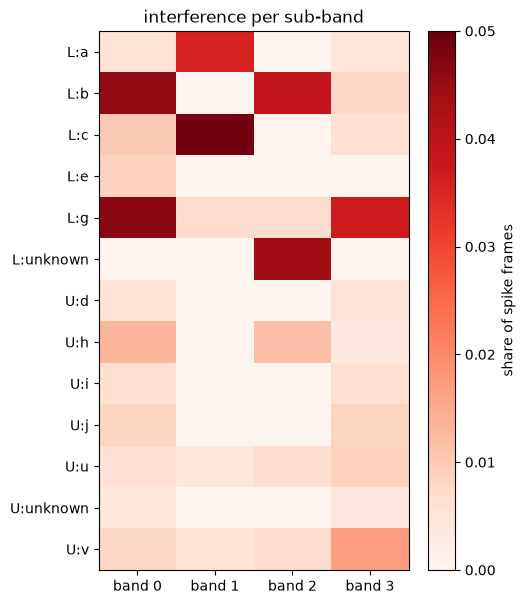

In [7]:
sp = win.assign(key=win.set + ":" + win.layout).groupby("key")[[f"spike_b{k}" for k in range(4)]].mean()
fig, ax = plt.subplots(figsize=(5, 7))
im = ax.imshow(sp.values, cmap="Reds", aspect="auto", vmin=0, vmax=0.05)
ax.set_yticks(range(len(sp))); ax.set_yticklabels(sp.index)
ax.set_xticks(range(4)); ax.set_xticklabels(["band 0", "band 1", "band 2", "band 3"])
plt.colorbar(im, label="share of spike frames"); ax.set_title("interference per sub-band")
plt.show()

## 5. Test of the "usual picture" idea on labelled rooms
For each labelled room, pretend its labels are unknown: its **usual picture** = median static profile over all its windows.
For every window: **distance to usual picture** = 1 - cosine similarity. If people block the signal, more people
should push the picture further away from the room's usual one.

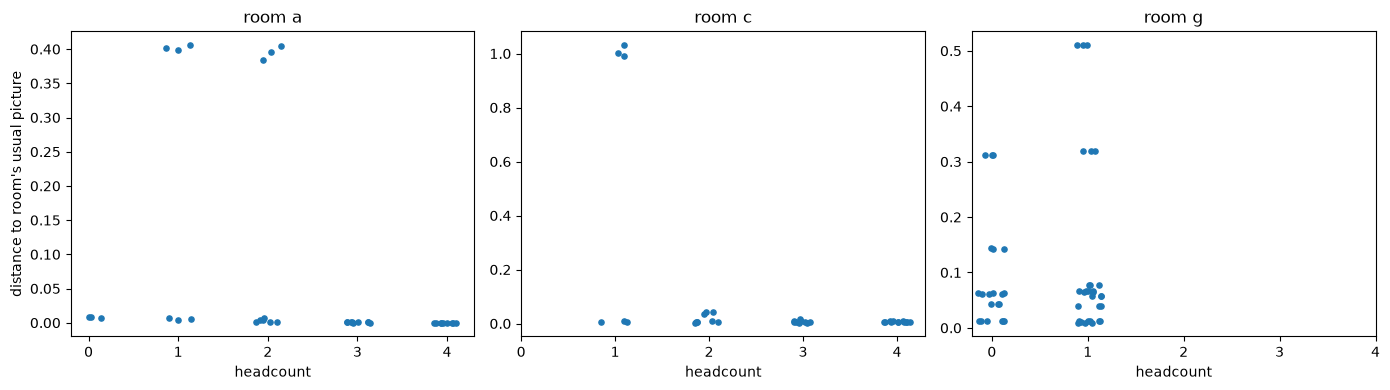

In [8]:
win["dist_to_usual"] = np.nan
for L in win[win.set == "L"].layout.unique():
    m = ((win.set == "L") & (win.layout == L)).values
    usual = np.median(prof[m], axis=0)
    usual = (usual - usual.mean()) / usual.std()
    win.loc[m, "dist_to_usual"] = 1 - prof[m] @ usual / len(usual)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=False)
for ax, L in zip(axes, ["a", "c", "g"]):
    d = win[(win.set == "L") & (win.layout == L)]
    ax.scatter(d.headcount + np.random.uniform(-0.15, 0.15, len(d)), d.dist_to_usual, s=14)
    ax.set_title(f"room {L}"); ax.set_xlabel("headcount"); ax.set_xticks(range(5))
axes[0].set_ylabel("distance to room's usual picture")
plt.tight_layout(); plt.show()


## Findings (2026-10-24)

1. **Unlabelled rooms form their own family.** d, h, i, j, u and the unknown U traces look alike (similarity ~0.6-0.85) but look very different from labelled rooms a, c, e, g (~0.0-0.2). Exceptions: labelled room b resembles the unlabelled rooms (0.5-0.8, i: 0.82), and v is somewhat close to a (0.42). The labelled rooms really are "odd" compared with where the test probably is.
2. **u and v are not uniform:** they split into sub-blocks (u inner similarity 0.67, v 0.52), so they hold several sessions / set-ups (or several physical rooms with the same layout).
3. **Unknown traces:** all 5 unlabelled unknowns look like room d (0.82-0.88). Two labelled unknowns look like e (0.82), one like g (0.73).
4. **Movement:** unlabelled rooms are mostly calm (dyn_ratio 1e-5 to 1e-4, like g) with a wide spread inside each room, so each probably mixes different situations.
5. **Interference is almost only in the labelled rooms.** a, b, c, g and the labelled unknowns have strong spikes on one sub-band; unlabelled rooms have nearly none. A model that uses spikes learns something that does not exist in the test rooms -> spikes must be cleaned.
6. **The simple "usual picture" test failed.** Distance to the room's median static profile does not grow with headcount. A few whole recordings sit far from the others (one 1-person and one 2-person trace in a, one 1-person in c): the frozen picture changes more between sessions (router moved? door open?) than between headcounts.
